# % Reason

In [ ]:
from google.colab import drive
from pathlib import Path
import pyarrow.dataset as ds
import pandas as pd
from IPython.display import display

drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/hmda")

# Đầu vào từ hai pipeline độc lập
S2_PANDAS_PATH = BASE / "clean_pandas" / "S2_denied"
S2_SPARK_PATH = BASE / "clean_spark" / "S2_denied"

# Kết quả của Thủy lưu riêng
DIAG_OUT = Path(
    "/content/drive/MyDrive/HMDA_Thuy/denial_diagnostics"
)
DIAG_OUT.mkdir(parents=True, exist_ok=True)

# Những cột cần cho phân tích lý do từ chối
DIAG_COLS = [
    "action_taken",
    "denial_reason_1",
    "denial_reason_2",
    "denial_reason_3",
    "denial_reason_4",
    "income",
    "debt_to_income_ratio",
    "dti_band",
    "combined_loan_to_value_ratio",
    "cltv_band",
    "loan_amount",
    "property_value",
]

checks = []

for engine, path in [
    ("Pandas", S2_PANDAS_PATH),
    ("Spark", S2_SPARK_PATH),
]:
    if not path.exists():
        raise FileNotFoundError(f"Chưa tìm thấy: {path}")

    dataset = ds.dataset(
        str(path),
        format="parquet",
        partitioning="hive",
    )

    missing_cols = [
        c for c in DIAG_COLS if c not in dataset.schema.names
    ]

    if missing_cols:
        raise ValueError(f"Bản {engine} thiếu cột: {missing_cols}")

    # Đếm dòng, chưa tải toàn bộ bảng vào RAM
    n = dataset.count_rows()

    checks.append({
        "prepared_by": engine,
        "rows": n,
        "expected_rows": 2_103_462,
        "rows_match": n == 2_103_462,
        "required_columns_available": True,
    })

input_checks = pd.DataFrame(checks)

print("\nKIỂM TRA DỮ LIỆU S2")
display(input_checks)

input_checks.to_csv(
    DIAG_OUT / "00_input_checks.csv",
    index=False,
    encoding="utf-8-sig",
)

if input_checks["rows_match"].all():
    print("\nOK — cả hai bản S2 đều đủ số dòng và cột cần dùng.")
else:
    print("\nSố dòng khác dự kiến — gửi output để kiểm tra.")

print("\nFolder kết quả:")
print("My Drive → HMDA_Thuy → denial_diagnostics")

Mounted at /content/drive

KIỂM TRA DỮ LIỆU S2


,prepared_by,rows,expected_rows,rows_match,required_columns_available
0,Pandas,2103462,2103462,True,True
1,Spark,2103462,2103462,True,True



OK — cả hai bản S2 đều đủ số dòng và cột cần dùng.

Folder kết quả:
My Drive → HMDA_Thuy → denial_diagnostics


In [ ]:
import pandas as pd
import numpy as np
import pyarrow.dataset as ds
from IPython.display import display

# 1. Đọc bản S2 được cleaning bằng Pandas
print("Đang đọc dữ liệu S2...")

s2_pd = (
    ds.dataset(
        str(S2_PANDAS_PATH),
        format="parquet",
        partitioning="hive",
    )
    .to_table(columns=DIAG_COLS)
    .to_pandas(strings_to_categorical=True)
)

# Kiểm tra toàn bộ hồ sơ đều có outcome denied
actions = s2_pd["action_taken"].astype("string")

assert len(s2_pd) == 2_103_462, "Số dòng S2 chưa khớp."
assert actions.eq("3").fillna(False).all(), (
    "S2 có hồ sơ không thuộc outcome denied."
)

# Mã dòng chỉ dùng trong notebook này.
# Giúp đếm một lý do tối đa một lần trong mỗi hồ sơ ở bước sau.
s2_pd["diag_id"] = np.arange(len(s2_pd), dtype=np.int64)

REASON_COLS = [
    "denial_reason_1",
    "denial_reason_2",
    "denial_reason_3",
    "denial_reason_4",
]

# 2. Chuẩn hóa cách biểu diễn mã, vẫn giữ missing
reason_codes_pd = pd.DataFrame({
    c: s2_pd[c].astype("string").str.strip().replace("", pd.NA)
    for c in REASON_COLS
})

# 3. Đếm từng mã ở từng vị trí
slot_counts = {}

for column in REASON_COLS:
    slot_counts[column] = (
        reason_codes_pd[column]
        .fillna("Missing")
        .value_counts()
    )

reason_slot_audit = (
    pd.DataFrame(slot_counts)
    .fillna(0)
    .astype("int64")
)

reason_slot_audit.index.name = "reported_code"
reason_slot_audit["total_slots"] = reason_slot_audit.sum(axis=1)
reason_slot_audit = reason_slot_audit.sort_values(
    "total_slots", ascending=False
)

# Mỗi cột lý do phải có đúng một ô cho mỗi hồ sơ
for column in REASON_COLS:
    assert reason_slot_audit[column].sum() == len(s2_pd)

# 4. Kiểm tra số ô có mã trên mỗi hồ sơ
# Đây chưa phải số lý do hợp lệ: có thể gồm mã không áp dụng.
filled_slots = reason_codes_pd.notna().sum(axis=1)

filled_slot_distribution = (
    filled_slots.value_counts()
    .reindex(range(5), fill_value=0)
    .sort_index()
    .rename_axis("filled_reason_slots")
    .reset_index(name="applications")
)

filled_slot_distribution["share_of_S2_pct"] = (
    filled_slot_distribution["applications"] / len(s2_pd) * 100
)

print("\nKIỂM TRA S2")
print(f"Số hồ sơ: {len(s2_pd):,}")
print("Toàn bộ action_taken = 3: OK")
print(
    f"RAM của s2_pd: "
    f"{s2_pd.memory_usage(deep=True).sum() / 1e9:.2f} GB"
)

print("\nBẢNG 1 — MÃ ĐƯỢC GHI TRONG TỪNG CỘT LÝ DO")
display(reason_slot_audit)

print("\nBẢNG 2 — SỐ Ô LÝ DO CÓ MÃ TRÊN MỖI HỒ SƠ")
display(filled_slot_distribution.round(2))

# 5. Lưu bảng kiểm tra
PANDAS_DIAG_OUT = DIAG_OUT / "pandas"
PANDAS_DIAG_OUT.mkdir(parents=True, exist_ok=True)

reason_slot_audit.to_csv(
    PANDAS_DIAG_OUT / "01_reason_slot_audit.csv",
    encoding="utf-8-sig",
)
filled_slot_distribution.to_csv(
    PANDAS_DIAG_OUT / "02_filled_slot_distribution.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nOK — đã đọc và kiểm tra bốn cột lý do.")

Đang đọc dữ liệu S2...

KIỂM TRA S2
Số hồ sơ: 2,103,462
Toàn bộ action_taken = 3: OK
RAM của s2_pd: 0.10 GB

BẢNG 1 — MÃ ĐƯỢC GHI TRONG TỪNG CỘT LÝ DO


,denial_reason_1,denial_reason_2,denial_reason_3,denial_reason_4,total_slots
reported_code,,,,,
Missing,28692,1646311,2018554,2087875,5781432
1,675577,92682,5334,251,773844
3,565727,106407,6958,480,679572
4,269095,62469,15074,462,347100
9,159753,80008,24648,11764,276173
7,252568,14332,2453,247,269600
6,81836,31090,9321,1242,123489
5,49720,49596,18520,827,118663
2,20030,20146,2383,268,42827



BẢNG 2 — SỐ Ô LÝ DO CÓ MÃ TRÊN MỖI HỒ SƠ


,filled_reason_slots,applications,share_of_S2_pct
0,0,28692,1.36
1,1,1617278,76.89
2,2,372879,17.73
3,3,69072,3.28
4,4,15541,0.74



OK — đã đọc và kiểm tra bốn cột lý do.


In [ ]:
import pandas as pd
from IPython.display import display

# 1. Tên chính thức của các mã lý do
REASON_LABELS = {
    "1": "Debt-to-income ratio",
    "2": "Employment history",
    "3": "Credit history",
    "4": "Collateral",
    "5": "Insufficient cash (downpayment, closing costs)",
    "6": "Unverifiable information",
    "7": "Credit application incomplete",
    "8": "Mortgage insurance denied",
    "9": "Other",
}

# Kiểm tra mã ngoài danh sách trước khi phân tích
observed_codes = set(
    reason_codes_pd.stack().dropna().astype(str).unique()
)
unexpected_codes = observed_codes - set(REASON_LABELS)

if unexpected_codes:
    raise ValueError(
        f"Có mã cần kiểm tra thêm: {sorted(unexpected_codes)}"
    )

# 2. Chuyển bốn cột thành bảng:
#    một dòng = một mã lý do được ghi cho một hồ sơ
reason_long_pd = reason_codes_pd.copy()
reason_long_pd.insert(
    0, "diag_id", s2_pd["diag_id"].to_numpy()
)

reason_long_pd = (
    reason_long_pd.melt(
        id_vars="diag_id",
        value_vars=REASON_COLS,
        var_name="reason_slot",
        value_name="reason_code",
    )
    .dropna(subset=["reason_code"])
)

reason_long_pd["reason_code"] = (
    reason_long_pd["reason_code"].astype("string")
)

# 3. Mỗi hồ sơ chỉ được tính một lần cho cùng một lý do
reason_membership_pd = (
    reason_long_pd[["diag_id", "reason_code"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

duplicate_reason_slots = (
    len(reason_long_pd) - len(reason_membership_pd)
)

# 4. Xác định số hồ sơ có / không có lý do
n_s2 = len(s2_pd)
n_with_reason = reason_membership_pd["diag_id"].nunique()
n_without_reason = n_s2 - n_with_reason

assert n_with_reason + n_without_reason == n_s2

# 5. Bảng tần suất từng lý do
reason_frequency_pd = (
    reason_membership_pd.groupby("reason_code")
    .size()
    .reindex(list(REASON_LABELS), fill_value=0)
    .rename("applications")
    .rename_axis("reason_code")
    .reset_index()
)

reason_frequency_pd["reason"] = (
    reason_frequency_pd["reason_code"].map(REASON_LABELS)
)

# Mẫu số 1: toàn bộ hồ sơ bị từ chối
reason_frequency_pd["share_of_all_denied_pct"] = (
    reason_frequency_pd["applications"] / n_s2 * 100
)

# Mẫu số 2: chỉ hồ sơ có ít nhất một lý do
reason_frequency_pd["share_of_reason_reported_pct"] = (
    reason_frequency_pd["applications"] / n_with_reason * 100
)

reason_frequency_pd = (
    reason_frequency_pd[
        [
            "reason_code",
            "reason",
            "applications",
            "share_of_all_denied_pct",
            "share_of_reason_reported_pct",
        ]
    ]
    .sort_values(
        ["applications", "reason_code"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

assert reason_frequency_pd["applications"].sum() == len(
    reason_membership_pd
)
assert reason_frequency_pd["applications"].le(n_with_reason).all()

# 6. Bảng kiểm tra độ bao phủ
reason_coverage_pd = pd.DataFrame(
    [
        {
            "metric": "All denied applications",
            "applications": n_s2,
            "share_of_S2_pct": 100.0,
        },
        {
            "metric": "At least one valid reason",
            "applications": n_with_reason,
            "share_of_S2_pct": n_with_reason / n_s2 * 100,
        },
        {
            "metric": "No valid reason in cleaned data",
            "applications": n_without_reason,
            "share_of_S2_pct": n_without_reason / n_s2 * 100,
        },
    ]
)

print("BẢNG 1 — ĐỘ BAO PHỦ CỦA LÝ DO TỪ CHỐI")
display(reason_coverage_pd.round(2))

print("\nBẢNG 2 — SỐ HỒ SƠ CÓ TỪNG LÝ DO")
display(reason_frequency_pd.round(2))

print(
    "\nSố ô lý do bị lặp trong cùng hồ sơ "
    f"(đã bỏ đếm trùng): {duplicate_reason_slots:,}"
)

# 7. Lưu bảng đầy đủ số thập phân để đối chiếu Spark sau
PANDAS_DIAG_OUT.mkdir(parents=True, exist_ok=True)

reason_coverage_pd.to_csv(
    PANDAS_DIAG_OUT / "03_reason_coverage.csv",
    index=False,
    encoding="utf-8-sig",
)

reason_frequency_pd.to_csv(
    PANDAS_DIAG_OUT / "04_reason_frequency.csv",
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame(
    [{
        "reported_reason_slots": len(reason_long_pd),
        "unique_application_reason_pairs": len(reason_membership_pd),
        "duplicate_reason_slots_removed": duplicate_reason_slots,
    }]
).to_csv(
    PANDAS_DIAG_OUT / "05_reason_dedup_audit.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nOK — đã thống kê lý do theo từng hồ sơ và lưu kết quả.")

BẢNG 1 — ĐỘ BAO PHỦ CỦA LÝ DO TỪ CHỐI


,metric,applications,share_of_S2_pct
0,All denied applications,2103462,100.00
1,At least one valid reason,2074770,98.64
2,No valid reason in cleaned data,28692,1.36



BẢNG 2 — SỐ HỒ SƠ CÓ TỪNG LÝ DO


,reason_code,reason,applications,share_of_all_denied_pct,share_of_reason_reported_pct
0,1,Debt-to-income ratio,773844,36.79,37.30
1,3,Credit history,679572,32.31,32.75
2,4,Collateral,347100,16.50,16.73
3,9,Other,276173,13.13,13.31
4,7,Credit application incomplete,269600,12.82,12.99
5,6,Unverifiable information,123489,5.87,5.95
6,5,"Insufficient cash (downpayment, closing costs)",118663,5.64,5.72
7,2,Employment history,42827,2.04,2.06
8,8,Mortgage insurance denied,1148,0.05,0.06



Số ô lý do bị lặp trong cùng hồ sơ (đã bỏ đếm trùng): 0

OK — đã thống kê lý do theo từng hồ sơ và lưu kết quả.


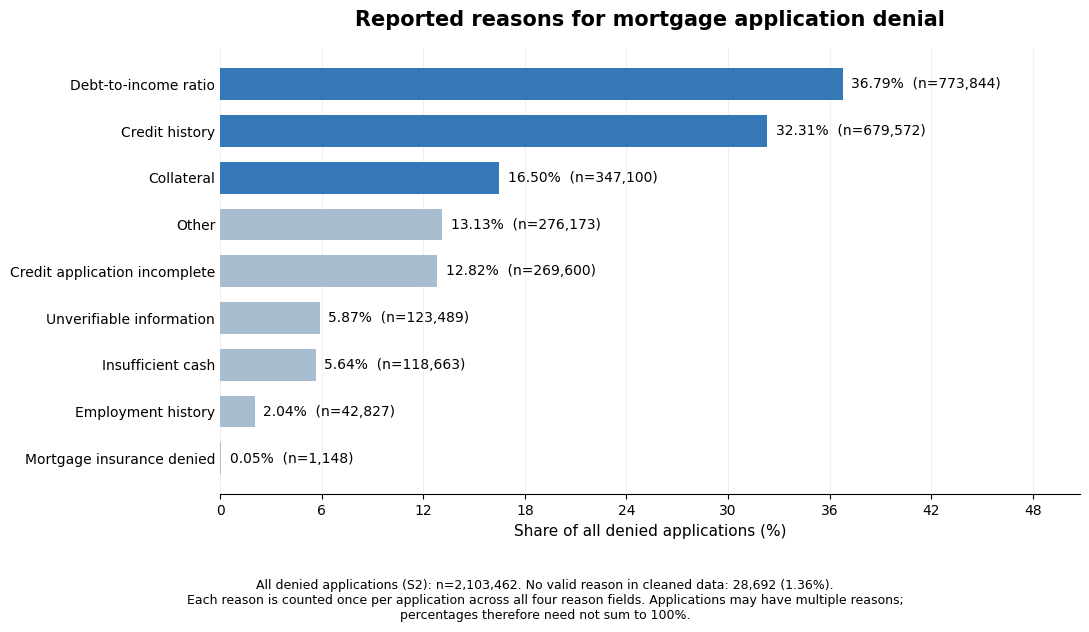

Đã lưu biểu đồ tại: /content/drive/MyDrive/HMDA_Thuy/denial_diagnostics/figures/01_denial_reason_frequency.png


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Nhãn ngắn để biểu đồ dễ đọc
SHORT_LABELS = {
    "1": "Debt-to-income ratio",
    "2": "Employment history",
    "3": "Credit history",
    "4": "Collateral",
    "5": "Insufficient cash",
    "6": "Unverifiable information",
    "7": "Credit application incomplete",
    "8": "Mortgage insurance denied",
    "9": "Other",
}

plot_df = reason_frequency_pd.sort_values(
    "applications", ascending=False
).copy()

plot_df["label"] = plot_df["reason_code"].map(SHORT_LABELS)

# Ba lý do phổ biến nhất được tô đậm
colors = [
    "#3478B8" if i < 3 else "#A9BDD0"
    for i in range(len(plot_df))
]

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.barh(
    plot_df["label"],
    plot_df["share_of_all_denied_pct"],
    color=colors,
    height=0.68,
)

ax.invert_yaxis()

# Ghi tỷ trọng và số hồ sơ bên cạnh từng thanh
for bar, pct, count in zip(
    bars,
    plot_df["share_of_all_denied_pct"],
    plot_df["applications"],
):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.2f}%  (n={count:,})",
        va="center",
        fontsize=10,
    )

ax.set_title(
    "Reported reasons for mortgage application denial",
    fontsize=15,
    fontweight="bold",
    pad=16,
)

ax.set_xlabel("Share of all denied applications (%)", fontsize=11)
ax.set_ylabel("")
ax.set_xlim(
    0,
    plot_df["share_of_all_denied_pct"].max() + 14,
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.tick_params(axis="y", length=0, labelsize=10)

fig.text(
    0.5,
    0.035,
    f"All denied applications (S2): n={n_s2:,}. "
    f"No valid reason in cleaned data: {n_without_reason:,} "
    f"({n_without_reason / n_s2 * 100:.2f}%).\n"
    "Each reason is counted once per application across all four reason fields. "
    "Applications may have multiple reasons;\n"
    "percentages therefore need not sum to 100%.",
    ha="center",
    va="bottom",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.14, 1, 1])

FIGURES_DIAG_OUT = DIAG_OUT / "figures"
FIGURES_DIAG_OUT.mkdir(parents=True, exist_ok=True)

figure_path = FIGURES_DIAG_OUT / "01_denial_reason_frequency.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"Đã lưu biểu đồ tại: {figure_path}")

# Profile Analysis

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

# 1. Các biến tài chính cần so sánh
# Giữ nguyên đơn vị trong dữ liệu khi tính và lưu.
FINANCIAL_VARS = {
    "income": ("Income", "Thousand USD/year"),
    "loan_amount": ("Loan amount", "USD"),
    "combined_loan_to_value_ratio": ("CLTV", "%"),
    "property_value": ("Property value", "USD"),
}

# Đặt mã hồ sơ làm index để chọn đúng các hồ sơ của mỗi nhóm
financial_base_pd = s2_pd.set_index("diag_id")[
    list(FINANCIAL_VARS)
].copy()

assert financial_base_pd.index.is_unique

for col in FINANCIAL_VARS:
    financial_base_pd[col] = pd.to_numeric(
        financial_base_pd[col], errors="coerce"
    )

# Không tự ý xóa giá trị bất thường còn lại:
# nếu có infinity thì dừng để kiểm tra
if np.isinf(financial_base_pd.to_numpy(dtype=float)).any():
    raise ValueError("Có giá trị vô cực; cần kiểm tra trước khi tính.")

# 2. Hàm tính thống kê cho một nhóm
def summarize_financial_group(frame, group_code, group_label):
    result = []
    n = len(frame)

    for col, (variable, unit) in FINANCIAL_VARS.items():
        values = frame[col].dropna()
        quantiles = values.quantile([0.25, 0.50, 0.75])

        result.append({
            "group_code": group_code,
            "group": group_label,
            "variable": variable,
            "unit": unit,
            "total_records": n,
            "valid_records": len(values),
            "missing_pct": (
                (n - len(values)) / n * 100 if n else np.nan
            ),
            "Q1": quantiles.loc[0.25],
            "median": quantiles.loc[0.50],
            "Q3": quantiles.loc[0.75],
            "IQR": quantiles.loc[0.75] - quantiles.loc[0.25],
        })

    return result

# 3. Mốc so sánh: toàn bộ hồ sơ bị từ chối
summary_rows = summarize_financial_group(
    financial_base_pd,
    "ALL",
    "All denied applications",
)

# 4. Thống kê riêng từng lý do
# Chọn theo số hồ sơ có lý do đó, không chỉ denial_reason_1
reason_order = reason_frequency_pd["reason_code"].tolist()

for code in reason_order:
    member_ids = reason_membership_pd.loc[
        reason_membership_pd["reason_code"].eq(code),
        "diag_id",
    ].to_numpy()

    group_data = financial_base_pd.loc[member_ids]

    expected_count = reason_frequency_pd.loc[
        reason_frequency_pd["reason_code"].eq(code),
        "applications",
    ].iloc[0]

    assert len(group_data) == expected_count

    summary_rows.extend(
        summarize_financial_group(
            group_data,
            code,
            REASON_LABELS[code],
        )
    )

# 5. Thêm nhóm không có lý do trong dữ liệu đã làm sạch
reported_ids = reason_membership_pd["diag_id"].unique()

no_reason_data = financial_base_pd.loc[
    ~financial_base_pd.index.isin(reported_ids)
]

assert len(no_reason_data) == n_without_reason

summary_rows.extend(
    summarize_financial_group(
        no_reason_data,
        "NO_REASON",
        "No valid reason in cleaned data",
    )
)

reason_financial_summary_pd = pd.DataFrame(summary_rows)

# 6. Bảng trung vị gọn để đọc
group_order = (
    ["All denied applications"]
    + [REASON_LABELS[code] for code in reason_order]
    + ["No valid reason in cleaned data"]
)

reason_financial_medians_pd = (
    reason_financial_summary_pd.pivot(
        index="group",
        columns="variable",
        values="median",
    )
    .reindex(group_order)
    .reindex(
        columns=["Income", "Loan amount", "CLTV", "Property value"]
    )
)

reason_financial_missing_pd = (
    reason_financial_summary_pd.pivot(
        index="group",
        columns="variable",
        values="missing_pct",
    )
    .reindex(group_order)
    .reindex(
        columns=["Income", "Loan amount", "CLTV", "Property value"]
    )
)

print("BẢNG 1 — TRUNG VỊ TÀI CHÍNH THEO LÝ DO")
print("Income: nghìn USD/năm; Loan amount và Property value: USD; CLTV: %")
display(reason_financial_medians_pd.round(2))

print("\nBẢNG 2 — TỶ LỆ THIẾU DỮ LIỆU TRONG TỪNG NHÓM (%)")
display(reason_financial_missing_pd.round(2))

# 7. Lưu đầy đủ kết quả để dùng cho report và đối chiếu Spark
reason_financial_summary_pd.to_csv(
    PANDAS_DIAG_OUT / "06_financial_summary_by_reason.csv",
    index=False,
    encoding="utf-8-sig",
)

reason_financial_medians_pd.to_csv(
    PANDAS_DIAG_OUT / "07_financial_medians_by_reason.csv",
    encoding="utf-8-sig",
)

reason_financial_missing_pd.to_csv(
    PANDAS_DIAG_OUT / "08_financial_missing_by_reason.csv",
    encoding="utf-8-sig",
)

print("\nOK — đã tính và lưu đặc điểm tài chính theo lý do từ chối.")
print(
    "Mỗi biến dùng các giá trị không thiếu riêng của biến đó. "
    "Các nhóm lý do có thể trùng hồ sơ."
)

BẢNG 1 — TRUNG VỊ TÀI CHÍNH THEO LÝ DO
Income: nghìn USD/năm; Loan amount và Property value: USD; CLTV: %


variable,Income,Loan amount,CLTV,Property value
group,,,,
All denied applications,82.0,125000.0,74.51,355000.0
Debt-to-income ratio,67.0,125000.0,74.27,395000.0
Credit history,78.0,95000.0,70.07,275000.0
Collateral,100.0,125000.0,81.65,345000.0
Other,90.0,135000.0,74.44,345000.0
Credit application incomplete,100.0,125000.0,69.86,395000.0
Unverifiable information,88.0,155000.0,75.00,335000.0
"Insufficient cash (downpayment, closing costs)",70.0,165000.0,80.00,205000.0
Employment history,66.0,155000.0,80.00,315000.0



BẢNG 2 — TỶ LỆ THIẾU DỮ LIỆU TRONG TỪNG NHÓM (%)


variable,Income,Loan amount,CLTV,Property value
group,,,,
All denied applications,7.28,0.0,17.88,10.94
Debt-to-income ratio,5.03,0.0,14.12,6.80
Credit history,5.00,0.0,24.38,11.38
Collateral,6.92,0.0,4.80,4.35
Other,8.42,0.0,21.84,8.54
Credit application incomplete,11.39,0.0,17.05,18.58
Unverifiable information,10.69,0.0,21.80,3.26
"Insufficient cash (downpayment, closing costs)",7.50,0.0,46.58,3.60
Employment history,16.83,0.0,17.76,6.45



OK — đã tính và lưu đặc điểm tài chính theo lý do từ chối.
Mỗi biến dùng các giá trị không thiếu riêng của biến đó. Các nhóm lý do có thể trùng hồ sơ.


In [ ]:
import pandas as pd
from IPython.display import display

# 1. Thứ tự các nhóm DTI đã được tạo trong bước làm sạch
DTI_ORDER = [
    "<20%",
    "20-<30%",
    "30-<36%",
    "36-43%",
    "44-49%",
    "50-60%",
    ">60%",
    "Missing",
]

# Chuyển giá trị thiếu thành nhóm Missing để không bỏ hồ sơ
dti_by_id_pd = s2_pd.set_index("diag_id")["dti_band"].astype("string")
dti_by_id_pd = dti_by_id_pd.str.strip().fillna("Missing")
dti_by_id_pd = dti_by_id_pd.replace("", "Missing")

unexpected_bands = set(dti_by_id_pd.unique()) - set(DTI_ORDER)

if unexpected_bands:
    raise ValueError(
        f"Có nhãn DTI cần kiểm tra: {sorted(unexpected_bands)}"
    )

# 2. Hàm tính phân bố DTI trong một nhóm hồ sơ
def summarize_dti_group(values, group_code, group_label):
    counts = values.value_counts().reindex(DTI_ORDER, fill_value=0)
    n = len(values)

    result = counts.rename("applications").rename_axis(
        "dti_band"
    ).reset_index()

    result.insert(0, "group", group_label)
    result.insert(0, "group_code", group_code)
    result["group_total"] = n

    # Mẫu số gồm tất cả hồ sơ trong nhóm, kể cả thiếu DTI
    result["share_within_group_pct"] = (
        result["applications"] / n * 100
        if n else float("nan")
    )

    assert result["applications"].sum() == n

    return result

# 3. Toàn bộ S2 làm mốc so sánh
dti_tables = [
    summarize_dti_group(
        dti_by_id_pd,
        "ALL",
        "All denied applications",
    )
]

# 4. Tính riêng từng nhóm lý do
for code in reason_order:
    member_ids = reason_membership_pd.loc[
        reason_membership_pd["reason_code"].eq(code),
        "diag_id",
    ].to_numpy()

    dti_tables.append(
        summarize_dti_group(
            dti_by_id_pd.loc[member_ids],
            code,
            REASON_LABELS[code],
        )
    )

# 5. Nhóm không có lý do trong dữ liệu đã làm sạch
dti_tables.append(
    summarize_dti_group(
        dti_by_id_pd.loc[
            ~dti_by_id_pd.index.isin(reported_ids)
        ],
        "NO_REASON",
        "No valid reason in cleaned data",
    )
)

reason_dti_distribution_pd = pd.concat(
    dti_tables, ignore_index=True
)

# 6. Bảng phần trăm: mỗi hàng là một nhóm hồ sơ
reason_dti_pct_pd = (
    reason_dti_distribution_pd.pivot(
        index="group",
        columns="dti_band",
        values="share_within_group_pct",
    )
    .reindex(index=group_order, columns=DTI_ORDER)
)

assert reason_dti_pct_pd.sum(axis=1).sub(100).abs().lt(1e-8).all()

print("PHÂN BỐ DTI TRONG TỪNG NHÓM LÝ DO (%)")
print("Mỗi hàng cộng lại bằng 100%, gồm cả nhóm Missing.")
display(reason_dti_pct_pd.round(2))

# 7. Bảng gọn tập trung vào DTI cao và dữ liệu thiếu
reason_high_dti_pd = pd.DataFrame(
    index=reason_dti_pct_pd.index
)

reason_high_dti_pd["DTI 50-60%"] = reason_dti_pct_pd["50-60%"]
reason_high_dti_pd["DTI >60%"] = reason_dti_pct_pd[">60%"]
reason_high_dti_pd["DTI missing"] = reason_dti_pct_pd["Missing"]

print("\nBẢNG GỌN — DTI CAO VÀ DTI THIẾU (%)")
display(reason_high_dti_pd.round(2))

# 8. Lưu kết quả đầy đủ, chưa làm tròn
reason_dti_distribution_pd.to_csv(
    PANDAS_DIAG_OUT / "09_dti_distribution_by_reason.csv",
    index=False,
    encoding="utf-8-sig",
)

reason_dti_pct_pd.to_csv(
    PANDAS_DIAG_OUT / "10_dti_percentages_by_reason.csv",
    encoding="utf-8-sig",
)

reason_high_dti_pd.to_csv(
    PANDAS_DIAG_OUT / "11_high_dti_by_reason.csv",
    encoding="utf-8-sig",
)

print("\nOK — đã kiểm tra và lưu phân bố DTI theo lý do.")

PHÂN BỐ DTI TRONG TỪNG NHÓM LÝ DO (%)
Mỗi hàng cộng lại bằng 100%, gồm cả nhóm Missing.


dti_band,<20%,20-<30%,30-<36%,36-43%,44-49%,50-60%,>60%,Missing
group,,,,,,,,
All denied applications,6.26,7.91,7.24,13.26,12.11,14.81,26.45,11.97
Debt-to-income ratio,2.4,0.78,0.85,3.15,8.96,24.8,55.94,3.12
Credit history,8.56,10.76,9.05,14.45,10.68,14.01,23.97,8.52
Collateral,6.72,10.81,10.84,20.6,16.47,12.7,14.34,7.52
Other,6.98,9.12,8.45,15.71,12.85,12.98,22.72,11.19
Credit application incomplete,6.47,9.47,8.56,15.84,13.17,7.38,7.37,31.74
Unverifiable information,9.8,9.91,9.65,19.05,17.42,10.72,16.76,6.69
"Insufficient cash (downpayment, closing costs)",3.91,7.78,8.26,16.22,16.69,17.08,21.5,8.57
Employment history,8.45,5.55,5.55,11.32,11.07,13.26,38.97,5.82



BẢNG GỌN — DTI CAO VÀ DTI THIẾU (%)


,DTI 50-60%,DTI >60%,DTI missing
group,,,
All denied applications,14.81,26.45,11.97
Debt-to-income ratio,24.8,55.94,3.12
Credit history,14.01,23.97,8.52
Collateral,12.7,14.34,7.52
Other,12.98,22.72,11.19
Credit application incomplete,7.38,7.37,31.74
Unverifiable information,10.72,16.76,6.69
"Insufficient cash (downpayment, closing costs)",17.08,21.5,8.57
Employment history,13.26,38.97,5.82



OK — đã kiểm tra và lưu phân bố DTI theo lý do.
